# Figure 5a: surface freshwater flux, Atlantic + GIN 60-65N, 8xCO2

Total surface freshwater flux, positive into the ocean, with the mean of the recovered state (year 4000 to the end).

Input: `SFWF_terms_ann_atlGIN60-65N_8x.nc`

In [1]:
import numpy as np
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import common

matplotlib.rc('font', size=16)

In [2]:
model_years, terms = common.freshwater_terms('8x')
years = model_years - common.BRANCH_YEAR
total = terms['Total']

RECOVERED_FROM = 4000  # first year of the recovered-state mean
recovered_mean = total[years >= RECOVERED_FROM].mean()
print(f'recovered-state mean (years {RECOVERED_FROM}-{years[-1]}): {recovered_mean:+.3f} mm/day')
smoothed = common.butterworth_lowpass(total)

recovered-state mean (years 4000-5169): +1.543 mm/day


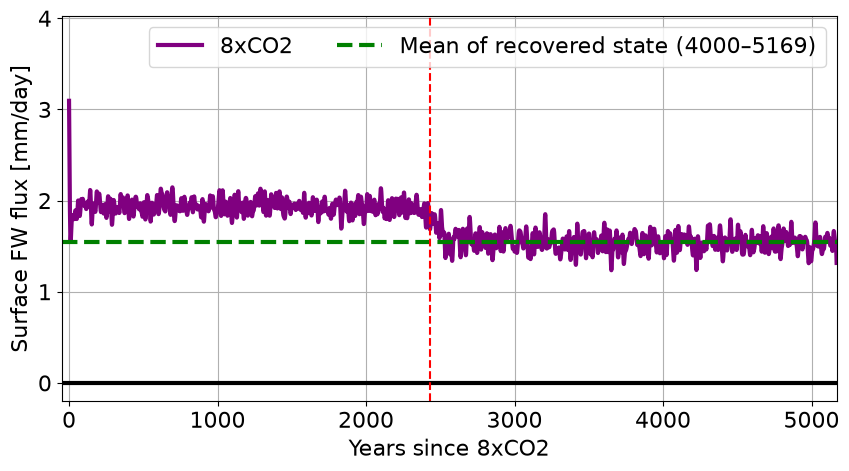

In [3]:
plt.subplots(figsize=(10, 5))
plt.plot(years, smoothed, linewidth=3, color='purple', label='8xCO2')
plt.axhline(recovered_mean, linewidth=3, color='green', linestyle='--',
            label=f'Mean of recovered state ({RECOVERED_FROM}–{years[-1]})')
plt.xlim(-common.X_START_PAD, years[-1])
plt.ylim(-0.2, 1.3 * smoothed.max())  # keep the zero line; leave room for the legend
plt.legend(ncol=2, loc='upper right')
plt.grid()
plt.xlabel('Years since 8xCO2')
plt.ylabel('Surface FW flux [mm/day]')
plt.axhline(0, color='black', linewidth=3)
plt.axvline(common.RECOVERY_YEAR, linestyle='--', color='red')
plt.savefig(common.figure_path('fig05a_surface_freshwater_flux.png'), dpi=150, bbox_inches='tight')
plt.show()